# EXP-001 Dummy

Người thực hiện: Jollibee (thích ăn mì cay)  
Ngày chạy: 13/11/2026  
Trạng thái: rerun

### Mục tiêu: Thiết lập đối chứng dự đoán lớp phổ biến


## Dữ liệu và phân bố nhãn

Bộ physiological68 gồm 68 đặc trưng và 6.189 cửa sổ từ 15 người. Cell dưới đếm nhãn thật từ bảng đầu vào. Nhị phân gộp Baseline và Amusement thành Non-stress.

In [6]:
from pathlib import Path

import pandas as pd

here = Path.cwd()
repo = next(
    folder for folder in (here, *here.parents)
    if (folder / "configs" / "defaults.yaml").is_file()
)
experiment = repo / "experiments/01_baselines/EXP-001_Dummy"

Tổng số cửa sổ mỗi bài toán: 6189


,Số cửa sổ
label_original,
Non-stress,4341
Stress,1848


,Số cửa sổ
label_original,
Baseline,3370
Stress,1848
Amusement,971


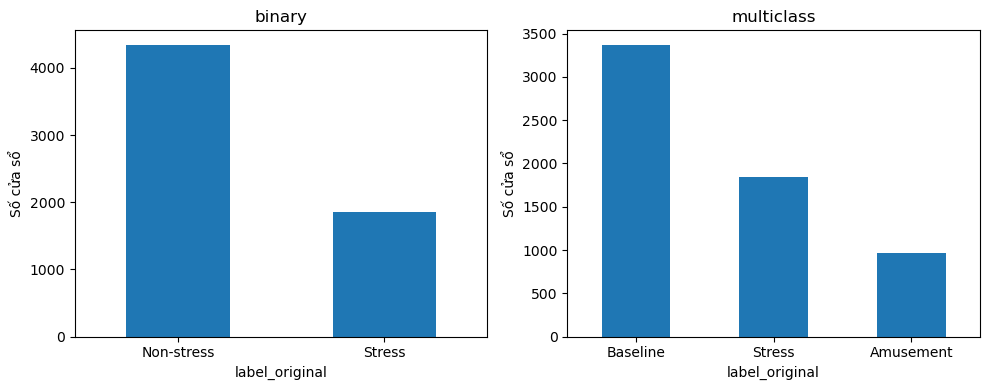

In [7]:
import matplotlib.pyplot as plt

dataset = repo / "data/features/g2_physiological68_group15_20261107/all_subjects.csv"
labels_original = pd.read_csv(dataset, usecols=["label_original"])["label_original"]
print(f"Tổng số cửa sổ mỗi bài toán: {len(labels_original)}")

label_names = {
    "binary": {1: "Non-stress", 2: "Stress", 3: "Non-stress"},
    "multiclass": {1: "Baseline", 2: "Stress", 3: "Amusement"},
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (task, labels) in zip(axes, label_names.items()):
    counts = (
        labels_original
        .map(labels)
        .value_counts()
        .reindex(list(dict.fromkeys(labels.values())), fill_value=0)
    )
    display(counts.rename(task).to_frame("Số cửa sổ"))
    counts.plot.bar(ax=ax, rot=0, title=task)
    ax.set_ylabel("Số cửa sổ")

fig.tight_layout()
figures = experiment / "figures"
figures.mkdir(exist_ok=True)
fig.savefig(figures / "label_distribution.png", dpi=150)
plt.show()

## Cấu hình Dummy

- Mô hình: `DummyClassifier(strategy="most_frequent")`
- Cấu hình chạy: `configs/defaults.yaml`
- Đánh giá: LOSO trên 15 người, riêng cho binary và multiclass.

Trong mỗi fold, Dummy tìm lớp phổ biến nhất trong dữ liệu của 14 người train,
rồi dự đoán lớp đó cho mọi cửa sổ của người test.

## Kết quả lượt chạy EXP-001

Bảng tính trung bình và độ lệch chuẩn theo 15 người cho từng bài toán.

In [8]:
results = pd.read_csv(experiment / "results.csv")
display(
    results.groupby("task")[["macro_f1", "balanced_accuracy"]]
    .agg(["mean", "std"])
    .round(4)
)

macro_f1         balanced_accuracy     
               mean     std              mean  std
task                                              
binary       0.4123  0.0035            0.5000  0.0
multiclass   0.2350  0.0023            0.3333  0.0

## So sánh các mô hình trên kết quả G3

In [9]:
g3 = pd.read_csv(repo / "reports" / "g3_group" / "metrics_by_subject.csv")

comparison = g3.groupby(["task", "model"])[
    ["macro_f1", "balanced_accuracy"]
].mean()

display(comparison.round(4))

macro_f1  balanced_accuracy
task       model                             
binary     dummy    0.4123             0.5000
           knn      0.7258             0.7541
           lr       0.8103             0.8304
           mlp      0.7986             0.8225
           rf       0.8735             0.8865
           svm      0.8424             0.8663
multiclass dummy    0.2350             0.3333
           knn      0.5555             0.5753
           lr       0.5894             0.6315
           mlp      0.6462             0.6815
           rf       0.6480             0.6700
           svm      0.6177             0.6595

## Phân tích và kết luận

Qua 15 lượt LOSO cho mỗi bài toán, Dummy đạt Macro-F1 trung bình
0,4123 và Balanced Accuracy 0,5000 ở bài toán nhị phân. Ở bài toán
ba lớp, hai chỉ số lần lượt là 0,2350 và 0,3333.

Biểu đồ nhãn thật cho thấy Non-stress chiếm nhiều cửa sổ nhất trong
bài toán nhị phân (4.341/6.189), còn Baseline chiếm nhiều cửa sổ nhất
trong bài toán ba lớp (3.370/6.189). Trong mỗi lượt test, Dummy luôn dự đoán cùng một lớp. Recall của lớp đó bằng 1 và recall của các lớp còn lại bằng 0. Balanced Accuracy là trung bình recall, bằng 0,5000 cho nhị phân và 0,3333 cho ba lớp.

Trong bảng đối chiếu G3, cả LR, KNN, SVM, Random Forest và MLP đều
có Macro-F1 và Balanced Accuracy trung bình cao hơn Dummy ở cả hai
bài toán. Kết quả Dummy là mốc đối chứng để đo mức cải thiện của
các mô hình học từ 68 đặc trưng sinh lý.